# EDA: прогноз дефицита курьеров

В этом файле я напишу свои инсайты после eda - поместил их наверх чтобы можно было сразу ознакомиться
1. Интересно понять логику проставления бинарного признака flag_high_load_lag_1, он выставляется если на протяжении всей недели каждый день был повышенный минчек? надо понять природу данного признака чтобы дальше работать, возможно он может иметь какие то особенности и ложную корреляцию с каким то признаками(что то похожее на мультиколлинеарность)
   Появляется интересное наблюдение: при flag_high_load_lag_1 = 0 target всегда равен нулю, при единице — всегда положителен.
2. target всегда >= fact_staff_churn, а в 72,2% строк они совпадают, опасно ориентироваться на такую закономерность, возможно в этом есть какой то дрифт по трейну, и в будущем может быть утечка данных, в целом логично что стоит предсказывать количество курьеров >= количества ушедших курьеров, чтобы устранить дефицит, думаю что это в целом проблема бизнеса, большая текучка курьеров операционно сказывается на весь бизнес, тк приходят на краткосрочную подработку.
   
4. Распределение таргета похоже на экспоненциальное распределение, среднее около 2 и длинный хвост справа, max = 31 курьер
   
6. Небольшое количество данных по отдельным дарксторам по 3 значение таргета на даркстор. Если рассматривать проблему холодного старта - появление новых дарксторов, то я бы рассмотрел решение через сравнение по основным параметрам с уже существующими дарксторами через knn(использовать параметры города, населения района который будет обслуживать даркстор и подобные параметры которые описывают дарксторы)

7. Нам дан train с информацией о дарксторах фактически только за последний месяц, мы бы могли добавить лаги с величиной в 1 год, чтобы фиксировать годовую сезонность, это следует обдумать, ведь условные пасхи\новые годы и тд являются лакомым куском для самоката, но возможно что на праздники включаются какие то бизнес-правила которые сами назначают курьеров на эти недели\дни

8. marketing_costs_lag_1 и fact_percent_lateness_lag_1 имеют большое количество пропусков, думаю что это чисто операционная проблема, что мы не получаем такие данные из datalake, хотя я думаю что эти признаки имеют хороший потенциал,в особенности маркетинговая нагрузка должна иметь прямую корреляцию колвом заказов и нагрузкой на дарксторы

9. У оттока и таргета корреляция = 0.92
10. flag_high_load_lag_1  и отток очень сильно коррелирует, думаю это можно объяснить тем что курьеры во время повышенной нагрузки больше доставляют заказов, устают и принимают решение уйти из компании

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')
TEST_DATE = pd.Timestamp('2025-11-24')
DATA_DIR = Path('.')

train = pd.read_csv(DATA_DIR / 'train.csv', parse_dates=['calendar_dt'])
facts = pd.read_csv(DATA_DIR / 'facts.csv', parse_dates=['calendar_dt'])
shifts = pd.read_csv(DATA_DIR / 'shifts_prediction.csv', parse_dates=['calendar_dt'])
test = pd.read_csv(DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

def wape(y_true, y_pred):
    return np.abs(np.asarray(y_true) - np.asarray(y_pred)).sum() / np.asarray(y_true).sum()

def safe_divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)

print('Данные загружены')

Данные загружены


## 1. Размеры, ключи, пропуски и описательные статистики

In [2]:
datasets = {'train': train, 'facts': facts, 'shifts_prediction': shifts, 'test': test, 'sample_submission': sample_submission}
overview_rows = []
missing_parts = []
for name, df in datasets.items():
    has_date = 'calendar_dt' in df.columns
    key = ['store_id'] + (['calendar_dt'] if has_date else [])
    overview_rows.append({
        'dataset': name, 'rows': len(df), 'columns': df.shape[1],
        'stores': df.store_id.nunique(),
        'dates': df.calendar_dt.nunique() if has_date else np.nan,
        'min_date': df.calendar_dt.min().date() if has_date else None,
        'max_date': df.calendar_dt.max().date() if has_date else None,
        'duplicate_keys': df.duplicated(key).sum(),
    })
    missing_parts.append(pd.DataFrame({
        'dataset': name, 'column': df.columns, 'dtype': df.dtypes.astype(str).values,
        'missing_n': df.isna().sum().values, 'missing_pct': 100 * df.isna().mean().values,
        'unique_n': df.nunique(dropna=True).values,
    }))
overview = pd.DataFrame(overview_rows).set_index('dataset')
missingness = pd.concat(missing_parts, ignore_index=True)
display(overview)
display(missingness.query('missing_n > 0').sort_values(['dataset', 'missing_pct'], ascending=[True, False]))
display(facts.select_dtypes('number').describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

assert train.duplicated(['calendar_dt', 'store_id']).sum() == 0
assert facts.duplicated(['calendar_dt', 'store_id']).sum() == 0
assert shifts.duplicated(['calendar_dt', 'store_id']).sum() == 0
assert test.store_id.is_unique and test.store_id.equals(sample_submission.store_id)
print('Ключи уникальны; порядок test совпадает с sample_submission.')

,rows,columns,stores,dates,min_date,max_date,duplicate_keys
dataset,,,,,,,
train,8220,3,2453,98.000,2024-01-01,2025-11-17,0
facts,10660,13,2455,99.000,2024-01-01,2025-11-24,0
shifts_prediction,223470,5,2742,100.000,2024-01-01,2025-12-01,0
test,2438,1,2438,NaN,None,None,0
sample_submission,2438,2,2438,NaN,None,None,0


,dataset,column,dtype,missing_n,missing_pct,unique_n
14,facts,marketing_costs_lag_1,float64,3203,30.047,7457
9,facts,fact_percent_lateness_lag_1,float64,2459,23.068,568
6,facts,fact_load_factor_lag_1,float64,117,1.098,944
15,facts,fact_couriers_with_shifts_lag_1,float64,117,1.098,39
20,shifts_prediction,predicted_load_factor,float64,199,0.089,1305


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
fact_staff_value_lag_1,"10,660.000",7.207,4.648,1.000,1.000,1.000,4.000,7.000,10.000,15.000,20.000,40.000
fact_load_factor_lag_1,"10,543.000",2.930,1.969,0.000,0.435,0.625,1.636,2.643,3.750,6.400,8.800,45.000
num_available_couriers_lag_1,"10,660.000",10.862,3.948,0.000,4.000,6.000,9.000,10.000,12.000,18.000,24.000,44.000
fact_num_orders_lag_1,"10,660.000",33.039,18.533,0.000,10.000,10.000,17.000,33.000,44.000,64.000,85.000,215.000
fact_percent_lateness_lag_1,"8,201.000",81.180,19.055,2.703,20.833,42.857,71.429,85.714,100.000,100.000,100.000,100.000
store_lifetime_in_days,"10,660.000",976.581,584.031,0.000,18.000,133.000,500.000,909.000,"1,450.000","1,957.100","2,279.000","2,527.000"
fact_staff_churn,"10,660.000",1.853,1.860,0.000,0.000,0.000,0.000,1.000,3.000,5.000,5.000,5.000
flag_high_load_lag_1,"10,660.000",0.678,0.467,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000,1.000
marketing_costs_lag_1,"7,457.000","41,402,957,480.921","829,709,677,473.254","7,559.291","1,565,859.095","5,445,942.696","61,267,570.502","449,906,780.118","3,649,712,685.500","68,428,064,835.710","494,204,800,690.875","62,838,677,091,818.852"
fact_couriers_with_shifts_lag_1,"10,543.000",12.689,5.145,1.000,4.000,6.000,9.000,12.000,15.000,22.000,28.000,40.000


Ключи уникальны; порядок test совпадает с sample_submission.


In [13]:
facts.isnull().sum()

calendar_dt                           0
store_id                              0
fact_staff_value_lag_1                0
fact_load_factor_lag_1              117
num_available_couriers_lag_1          0
fact_num_orders_lag_1                 0
fact_percent_lateness_lag_1        2459
city_nm                               0
store_lifetime_in_days                0
fact_staff_churn                      0
flag_high_load_lag_1                  0
marketing_costs_lag_1              3203
fact_couriers_with_shifts_lag_1     117
dtype: int64

## 2. Временное покрытие и длина истории

,train,facts,shifts_prediction
calendar_dt,,,
2025-08-25,13.000,13.000,"2,490.000"
2025-09-01,13.000,13.000,"2,490.000"
2025-09-08,13.000,13.000,"2,490.000"
2025-09-15,13.000,13.000,"2,490.000"
2025-09-22,13.000,13.000,"2,495.000"
2025-09-29,13.000,13.000,"2,505.000"
2025-10-06,13.000,13.000,"2,509.000"
2025-10-13,13.000,13.000,"2,506.000"
2025-10-20,13.000,13.000,"2,506.000"


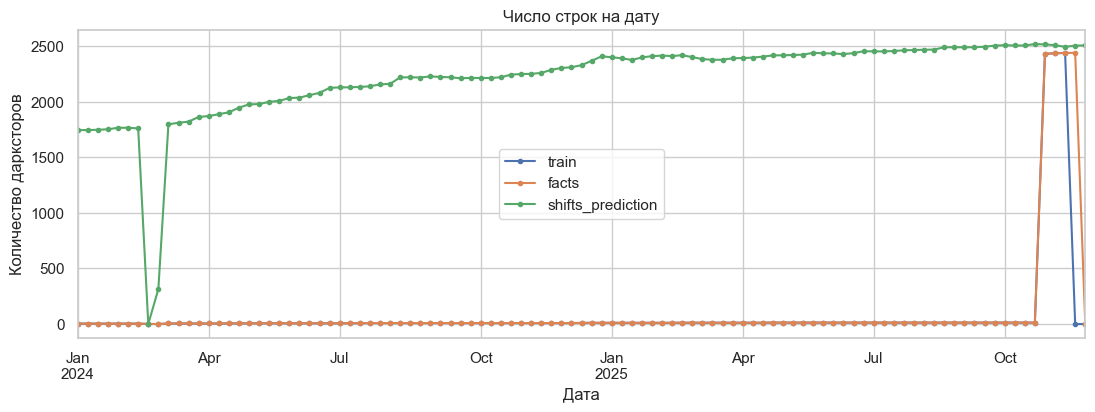

,stores,store_share_pct
target_weeks,,
1,4,0.163
2,6,0.245
3,2430,99.062
27,1,0.041
36,1,0.041
45,1,0.041
46,1,0.041
67,1,0.041
69,1,0.041


Ровно три target: 2,430 из 2,453 дарксторов (99.1%).


In [4]:
coverage = pd.concat([
    train.groupby('calendar_dt').size().rename('train'),
    facts.groupby('calendar_dt').size().rename('facts'),
    shifts.groupby('calendar_dt').size().rename('shifts_prediction'),
], axis=1).fillna(0)
display(coverage.tail(15))
fig, ax = plt.subplots(figsize=(13, 4))
coverage.plot(ax=ax, marker='o', markersize=3)
ax.set(title='Число строк на дату', xlabel='Дата', ylabel='Количество дарксторов')
plt.show()

history_lengths = train.groupby('store_id').size()
history_distribution = history_lengths.value_counts().sort_index().rename_axis('target_weeks').to_frame('stores')
history_distribution['store_share_pct'] = 100 * history_distribution.stores / history_distribution.stores.sum()
display(history_distribution)
print(f'Ровно три target: {(history_lengths == 3).sum():,} из {history_lengths.size:,} дарксторов ({(history_lengths == 3).mean():.1%}).')

## 3. Target: распределение и изменение по неделям

,value
count,"8,220.000"
mean,2.379
std,2.738
min,0.000
50%,2.000
75%,4.000
90%,6.000
95%,7.000
99%,12.000
max,31.000


,stores,target_sum,target_mean,target_median,zero_share
calendar_dt,,,,,
2025-08-11,13,13.000,1.000,0.000,0.615
2025-08-18,13,22.000,1.692,0.000,0.538
2025-08-25,13,24.000,1.846,1.000,0.462
2025-09-01,13,20.000,1.538,1.000,0.385
2025-09-08,13,31.000,2.385,2.000,0.385
2025-09-15,13,40.000,3.077,0.000,0.538
2025-09-22,13,25.000,1.923,1.000,0.154
2025-09-29,13,34.000,2.615,1.000,0.231
2025-10-06,13,23.000,1.769,2.000,0.462


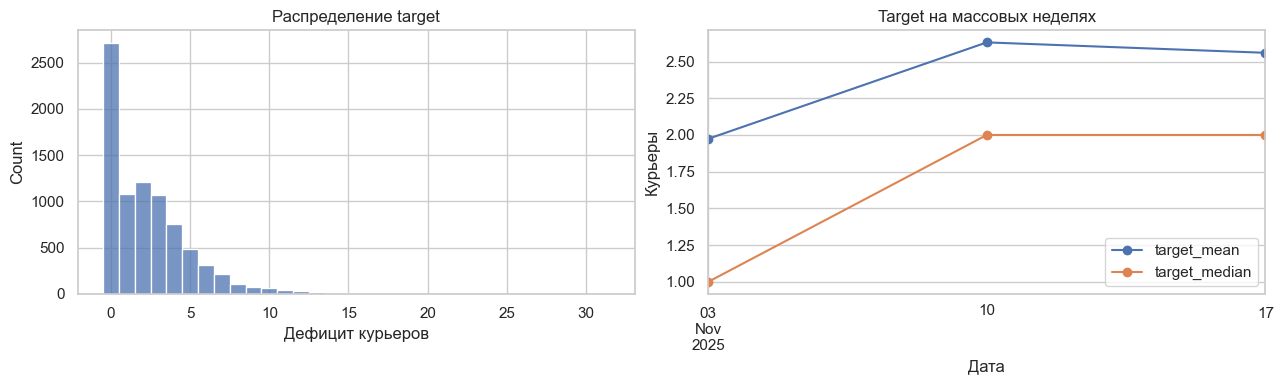

In [5]:
target_summary = train.target.describe(percentiles=[.5, .75, .9, .95, .99]).to_frame('value')
target_summary.loc['zero_share'] = (train.target == 0).mean()
weekly_target = train.groupby('calendar_dt').agg(
    stores=('store_id', 'size'), target_sum=('target', 'sum'),
    target_mean=('target', 'mean'), target_median=('target', 'median'),
    zero_share=('target', lambda x: (x == 0).mean()),
)
display(target_summary)
display(weekly_target.tail(15))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train.target, discrete=True, ax=axes[0])
axes[0].set(title='Распределение target', xlabel='Дефицит курьеров')
recent_weekly = weekly_target.query('stores > 100')
recent_weekly[['target_mean', 'target_median']].plot(marker='o', ax=axes[1])
axes[1].set(title='Target на массовых неделях', xlabel='Дата', ylabel='Курьеры')
plt.tight_layout(); plt.show()

## 4. Объединение таблиц и производные бизнес-признаки

In [6]:
model_data = (train.merge(facts, on=['calendar_dt', 'store_id'], how='left', validate='one_to_one')
                   .merge(shifts, on=['calendar_dt', 'store_id'], how='left', validate='one_to_one'))
assert model_data.city_nm.notna().all()
model_data['residual_to_churn'] = model_data.target - model_data.fact_staff_churn
model_data['available_after_churn'] = model_data.num_available_couriers_lag_1 - model_data.fact_staff_churn
model_data['predicted_staff_gap_available'] = model_data.predicted_staff_value - model_data.num_available_couriers_lag_1
model_data['predicted_staff_gap_after_churn'] = model_data.predicted_staff_value - model_data.available_after_churn
model_data['fact_staff_gap_available'] = model_data.fact_staff_value_lag_1 - model_data.num_available_couriers_lag_1
model_data['fact_staff_gap_with_shifts'] = model_data.fact_staff_value_lag_1 - model_data.fact_couriers_with_shifts_lag_1
model_data['churn_rate'] = safe_divide(model_data.fact_staff_churn, model_data.num_available_couriers_lag_1)
model_data['shift_participation_rate'] = safe_divide(model_data.fact_couriers_with_shifts_lag_1, model_data.num_available_couriers_lag_1)
model_data['orders_per_available_courier'] = safe_divide(model_data.fact_num_orders_lag_1, model_data.num_available_couriers_lag_1)
model_data['predicted_orders_growth_vs_fact'] = safe_divide(model_data.predicted_num_orders, model_data.fact_num_orders_lag_1)
print(f'Объединено {len(model_data):,} строк; отсутствующих predicted_staff_value: {model_data.predicted_staff_value.isna().sum()}.')

Объединено 8,220 строк; отсутствующих predicted_staff_value: 1.


## 5. Флаг повышенной нагрузки: target, операционные показатели и инерция

target,target_positive,target_zero,All
flag_high_load_lag_1,,,
0,0,2712,2712
1,5508,0,5508
All,5508,2712,8220


flag_high_load_lag_1                         0       1
target                          mean     0.000   3.550
                                median   0.000   3.000
fact_staff_churn                mean     0.000   2.706
                                median   0.000   3.000
fact_load_factor_lag_1          mean     2.754   2.728
                                median   2.372   2.500
fact_percent_lateness_lag_1     mean    69.886  82.154
                                median  73.333  86.364
fact_num_orders_lag_1           mean    28.651  31.828
                                median  27.000  31.000
fact_staff_value_lag_1          mean     5.360   7.195
                                median   6.000   7.000
num_available_couriers_lag_1    mean    11.378  10.538
                                median  10.000  10.000
fact_couriers_with_shifts_lag_1 mean    11.919  13.048
                                median  11.000  12.000
predicted_staff_value           mean     7.492   8.551
                                median   7.000   8.000
predicted_num_orders            mean   331.589 324.191
                                median 310.000 300.000
predicted_load_factor           mean     5.972   4.942
                                median   5.730   4.800

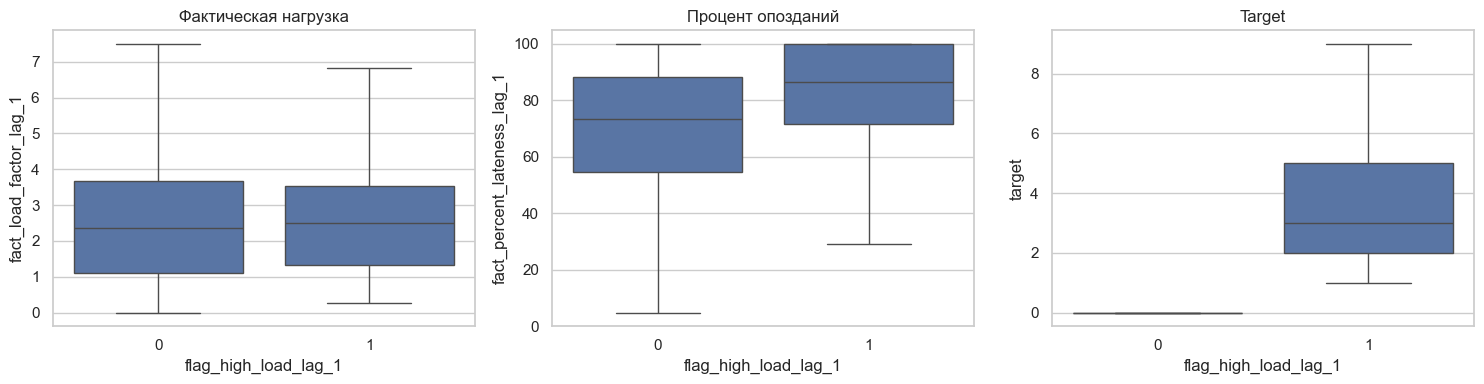

flag_high_load_lag_1,0,1
previous_flag,,
0.000,1646,1060
1.000,845,4650


flag_high_load_lag_1,0,1
previous_flag,,
0.000,60.800,39.200
1.000,15.400,84.600


,count,sum,mean
calendar_dt,,,
2025-09-22,13,11,0.846
2025-09-29,13,10,0.769
2025-10-06,13,7,0.538
2025-10-13,13,5,0.385
2025-10-20,13,8,0.615
2025-10-27,13,8,0.615
2025-11-03,2431,1491,0.613
2025-11-10,2436,1783,0.732
2025-11-17,2439,1728,0.708


In [7]:
flag_target = pd.crosstab(model_data.flag_high_load_lag_1, model_data.target.eq(0), margins=True).rename(columns={False: 'target_positive', True: 'target_zero'})
display(flag_target)
flag_metrics = ['target', 'fact_staff_churn', 'fact_load_factor_lag_1', 'fact_percent_lateness_lag_1',
                'fact_num_orders_lag_1', 'fact_staff_value_lag_1', 'num_available_couriers_lag_1',
                'fact_couriers_with_shifts_lag_1', 'predicted_staff_value', 'predicted_num_orders',
                'predicted_load_factor']
display(model_data.groupby('flag_high_load_lag_1')[flag_metrics].agg(['mean', 'median']).T)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=model_data, x='flag_high_load_lag_1', y='fact_load_factor_lag_1', showfliers=False, ax=axes[0])
sns.boxplot(data=model_data, x='flag_high_load_lag_1', y='fact_percent_lateness_lag_1', showfliers=False, ax=axes[1])
sns.boxplot(data=model_data, x='flag_high_load_lag_1', y='target', showfliers=False, ax=axes[2])
axes[0].set_title('Фактическая нагрузка'); axes[1].set_title('Процент опозданий'); axes[2].set_title('Target')
plt.tight_layout(); plt.show()

ordered_facts = facts.sort_values(['store_id', 'calendar_dt']).copy()
ordered_facts['previous_date'] = ordered_facts.groupby('store_id').calendar_dt.shift()
ordered_facts['previous_flag'] = ordered_facts.groupby('store_id').flag_high_load_lag_1.shift()
consecutive = ordered_facts[(ordered_facts.calendar_dt - ordered_facts.previous_date).dt.days.eq(7)]
transition_counts = pd.crosstab(consecutive.previous_flag, consecutive.flag_high_load_lag_1)
transition_rates = pd.crosstab(consecutive.previous_flag, consecutive.flag_high_load_lag_1, normalize='index')
display(transition_counts)
display((100 * transition_rates).round(1).rename_axis('previous_flag'))
display(facts.groupby('calendar_dt').flag_high_load_lag_1.agg(['count', 'sum', 'mean']).tail(10))

## 6. Churn, дополнительный дефицит, корреляции и простые правила

,value
target_equals_churn_share,0.722
target_below_churn_rows,0.000
churn_baseline_wape,0.238
flag_0_with_nonzero_churn,0.000


,residual_to_churn
count,"5,508.000"
mean,0.844
std,1.685
min,0.000
25%,0.000
50%,0.000
75%,1.000
90%,2.000
95%,3.000
99%,8.000


,corr_target,corr_residual_flag_1
churn_rate,0.716,0.215
predicted_staff_gap_after_churn,0.663,0.337
predicted_load_factor,-0.407,-0.224
predicted_staff_gap_available,0.367,0.273
predicted_staff_value,0.362,0.332
fact_staff_gap_available,0.357,0.249
fact_percent_lateness_lag_1,0.255,0.110
orders_per_available_courier,0.222,0.194
shift_participation_rate,0.153,0.046
fact_staff_gap_with_shifts,0.077,0.078


,rule,wape,exact_match_share
0,churn,0.238,0.722
4,churn + positive fact shift gap,0.263,0.695
1,"max(churn, positive predicted gap)",NaN,0.719
2,churn + positive predicted gap,NaN,0.697
3,churn + positive forecast growth,NaN,0.581


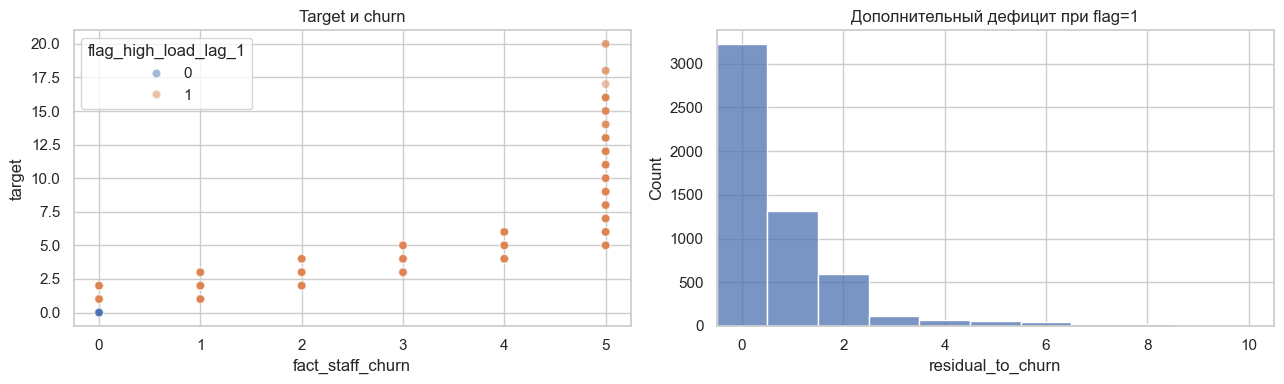

In [8]:
positive_flag = model_data.query('flag_high_load_lag_1 == 1')
churn_checks = pd.Series({
    'target_equals_churn_share': (model_data.target == model_data.fact_staff_churn).mean(),
    'target_below_churn_rows': (model_data.target < model_data.fact_staff_churn).sum(),
    'churn_baseline_wape': wape(model_data.target, model_data.fact_staff_churn),
    'flag_0_with_nonzero_churn': ((model_data.flag_high_load_lag_1 == 0) & (model_data.fact_staff_churn != 0)).sum(),
})
display(churn_checks.to_frame('value'))
residual_summary = positive_flag.residual_to_churn.describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame()
residual_summary.loc['zero_share'] = (positive_flag.residual_to_churn == 0).mean()
residual_summary.loc['positive_share'] = (positive_flag.residual_to_churn > 0).mean()
display(residual_summary)

business_features = ['predicted_staff_gap_available', 'predicted_staff_gap_after_churn',
                     'fact_staff_gap_available', 'fact_staff_gap_with_shifts', 'churn_rate',
                     'shift_participation_rate', 'orders_per_available_courier',
                     'fact_percent_lateness_lag_1', 'predicted_staff_value', 'predicted_load_factor']
correlations = pd.DataFrame({
    'corr_target': model_data[business_features].corrwith(model_data.target),
    'corr_residual_flag_1': positive_flag[business_features].corrwith(positive_flag.residual_to_churn),
}).sort_values('corr_target', key=np.abs, ascending=False)
display(correlations)

flag = model_data.flag_high_load_lag_1.to_numpy(); churn = model_data.fact_staff_churn.to_numpy()
available = model_data.num_available_couriers_lag_1.to_numpy(); predicted_staff = model_data.predicted_staff_value.to_numpy()
fact_staff = model_data.fact_staff_value_lag_1.to_numpy()
with_shifts = model_data.fact_couriers_with_shifts_lag_1.fillna(model_data.num_available_couriers_lag_1).to_numpy()
rules = {
    'churn': churn,
    'max(churn, positive predicted gap)': np.maximum(churn, np.maximum(0, predicted_staff - available)),
    'churn + positive predicted gap': churn + np.maximum(0, predicted_staff - available),
    'churn + positive forecast growth': churn + np.maximum(0, predicted_staff - fact_staff),
    'churn + positive fact shift gap': churn + np.maximum(0, fact_staff - with_shifts),
}
rule_rows = []
for name, prediction in rules.items():
    prediction = np.where(flag == 0, 0, prediction)
    rule_rows.append({'rule': name, 'wape': wape(model_data.target, prediction),
                      'exact_match_share': (np.rint(prediction) == model_data.target).mean()})
display(pd.DataFrame(rule_rows).sort_values('wape'))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=model_data.sample(min(3000, len(model_data)), random_state=42), x='fact_staff_churn', y='target', hue='flag_high_load_lag_1', alpha=.5, ax=axes[0])
sns.histplot(positive_flag.residual_to_churn, discrete=True, ax=axes[1])
axes[0].set_title('Target и churn'); axes[1].set(title='Дополнительный дефицит при flag=1', xlim=(-.5, 10.5))
plt.tight_layout(); plt.show()

## 7. Прогнозные ряды, тестовая неделя и train–test drift

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
predicted_staff_value_diff_1,"2,496.000",0.139,1.025,-13.000,-2.000,-1.000,0.000,0.000,1.000,1.000,2.000,9.000
predicted_num_orders_diff_1,"2,496.000",3.045,39.791,-600.000,-80.000,-40.000,-10.000,0.000,20.000,50.000,100.000,370.000
predicted_load_factor_diff_1,"2,496.000",-0.043,0.265,-5.130,-0.300,-0.300,-0.200,0.000,0.100,0.291,0.450,2.218


,feature,train_mean,test_mean,train_median,test_median,standardized_mean_diff,train_missing_pct,test_missing_pct
4,fact_percent_lateness_lag_1,82.140,87.769,85.714,90.399,0.370,0.164,0.000
10,predicted_staff_value,8.304,8.459,8.000,8.000,0.048,0.000,0.000
8,marketing_costs_lag_1,"77,164,883,641.262","36,222,276,961.809","467,126,720.327","464,630,117.321",-0.035,31.078,29.491
0,fact_staff_value_lag_1,9.169,9.293,8.000,9.000,0.034,0.000,0.000
12,predicted_load_factor,5.357,5.312,5.140,5.100,-0.032,0.000,0.000
1,fact_load_factor_lag_1,3.622,3.573,3.182,3.125,-0.029,0.410,0.246
11,predicted_num_orders,336.380,339.848,310.000,320.000,0.027,0.000,0.000
3,fact_num_orders_lag_1,41.052,40.674,38.000,38.000,-0.024,0.000,0.000
6,fact_staff_churn,1.949,1.986,2.000,2.000,0.020,0.000,0.000
2,num_available_couriers_lag_1,10.938,11.019,10.000,10.000,0.019,0.000,0.000


,stores,share
flag_high_load_lag_1,,
0,724,0.297
1,1714,0.703


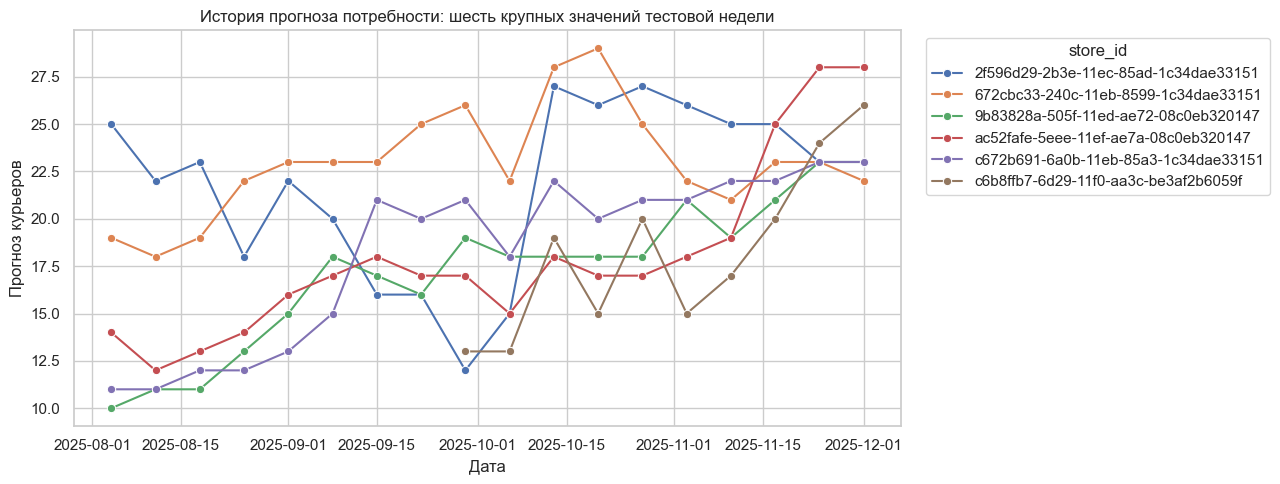

In [9]:
ordered_shifts = shifts.sort_values(['store_id', 'calendar_dt']).copy()
forecast_columns = ['predicted_staff_value', 'predicted_num_orders', 'predicted_load_factor']
for column in forecast_columns:
    ordered_shifts[f'{column}_lag_1'] = ordered_shifts.groupby('store_id')[column].shift()
    ordered_shifts[f'{column}_diff_1'] = ordered_shifts[column] - ordered_shifts[f'{column}_lag_1']
latest_forecasts = ordered_shifts.query('calendar_dt == @TEST_DATE')
display(latest_forecasts[[c for c in latest_forecasts if c.endswith('_diff_1')]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

test_features = (test.assign(calendar_dt=TEST_DATE)
                     .merge(facts, on=['calendar_dt', 'store_id'], how='left', validate='one_to_one')
                     .merge(shifts, on=['calendar_dt', 'store_id'], how='left', validate='one_to_one'))
last_train_date = train.calendar_dt.max()
last_train_features = model_data.query('calendar_dt == @last_train_date')
numeric_raw = [c for c in facts.select_dtypes('number').columns if c in test_features.columns] + forecast_columns
drift_rows = []
for column in numeric_raw:
    a, b = last_train_features[column], test_features[column]
    pooled_std = np.sqrt((a.var() + b.var()) / 2)
    drift_rows.append({'feature': column, 'train_mean': a.mean(), 'test_mean': b.mean(),
                       'train_median': a.median(), 'test_median': b.median(),
                       'standardized_mean_diff': (b.mean() - a.mean()) / pooled_std if pooled_std > 0 else 0,
                       'train_missing_pct': 100 * a.isna().mean(), 'test_missing_pct': 100 * b.isna().mean()})
drift = pd.DataFrame(drift_rows).sort_values('standardized_mean_diff', key=np.abs, ascending=False)
display(drift)
test_flag_summary = test_features.flag_high_load_lag_1.value_counts().sort_index().to_frame('stores')
test_flag_summary['share'] = test_flag_summary.stores / test_flag_summary.stores.sum()
display(test_flag_summary)

sample_stores = latest_forecasts.nlargest(6, 'predicted_staff_value').store_id
plot_data = shifts[shifts.store_id.isin(sample_stores) & (shifts.calendar_dt >= '2025-08-01')]
fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=plot_data, x='calendar_dt', y='predicted_staff_value', hue='store_id', marker='o', ax=ax)
ax.set(title='История прогноза потребности: шесть крупных значений тестовой недели', xlabel='Дата', ylabel='Прогноз курьеров')
ax.legend(title='store_id', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

## 8. Пропуски, города, корреляции и выбросы

,column,missing_rows,target_mean_missing,target_mean_present,flag_rate_missing,flag_rate_present
2,marketing_costs_lag_1,2484,2.453,2.346,0.681,0.665
1,fact_percent_lateness_lag_1,2457,2.016,2.533,0.615,0.693
0,fact_load_factor_lag_1,109,7.046,2.316,0.798,0.668
3,fact_couriers_with_shifts_lag_1,109,7.046,2.316,0.798,0.668


,rows,stores,target_mean,target_median,target_sum,zero_share,flag_rate,churn_mean
city_nm,,,,,,,,
Москва,2185,638,1.781,1.000,"3,891.000",0.477,0.523,1.335
Санкт-Петербург,1100,262,3.434,3.000,"3,777.000",0.215,0.785,2.461
Новосибирск,255,85,3.439,3.000,877.000,0.204,0.796,2.408
Казань,200,56,1.065,0.000,213.000,0.585,0.415,0.815
Нижний Новгород,192,64,1.786,1.000,343.000,0.401,0.599,1.417
Краснодар,192,64,2.151,2.000,413.000,0.255,0.745,1.755
Екатеринбург,183,61,3.317,3.000,607.000,0.142,0.858,2.541
Красноярск,183,61,1.077,0.000,197.000,0.607,0.393,0.820
Саратов,171,31,1.070,0.000,183.000,0.550,0.450,0.889


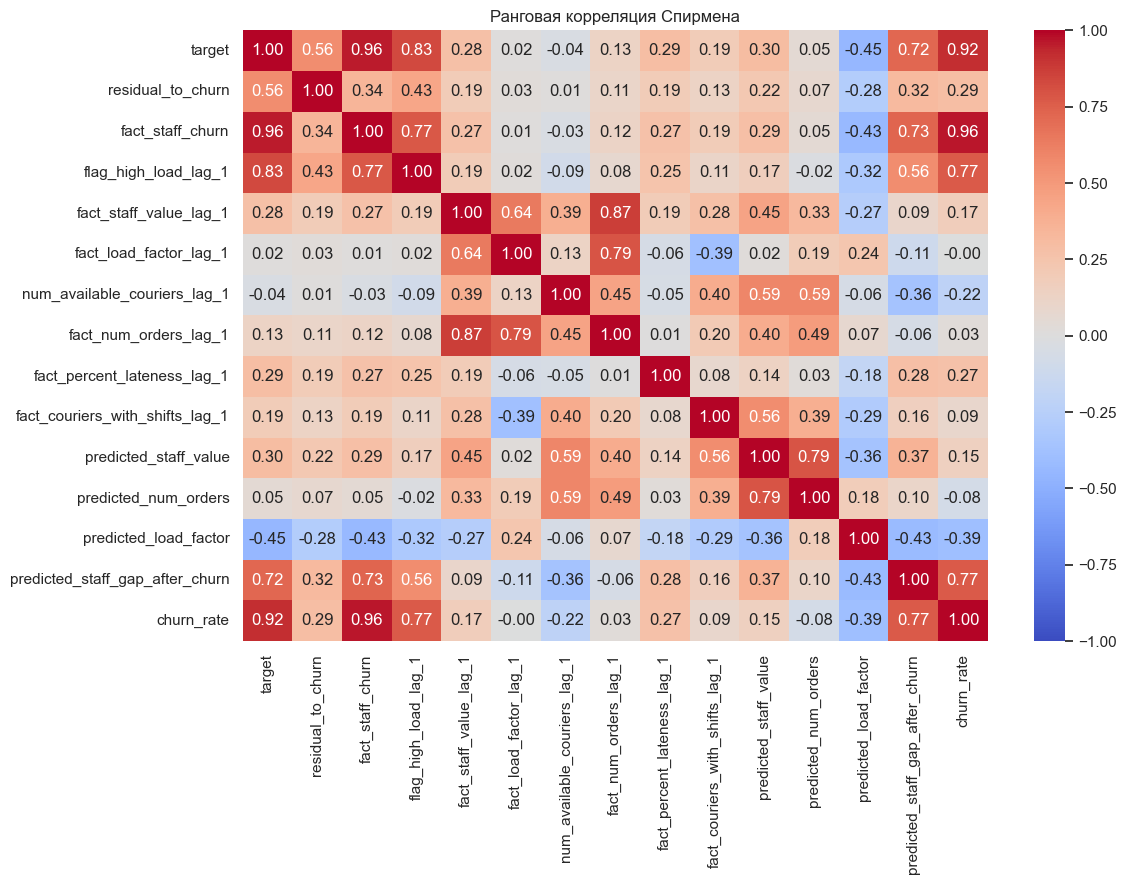

,min,p01,median,p95,p99,max,max_to_p99
marketing_costs_lag_1,"7,559.291","1,518,231.849","445,088,537.955","65,189,657,534.614","486,394,205,090.525","62,838,677,091,818.852",129.193
shift_participation_rate,0.030,0.444,1.143,2.125,2.625,18.000,6.857
churn_rate,0.000,0.000,0.125,0.556,0.833,5.000,6.000
fact_load_factor_lag_1,0.000,0.417,2.474,6.200,8.667,45.000,5.192
orders_per_available_courier,0.000,1.000,3.059,5.417,7.400,34.000,4.595
residual_to_churn,0.000,0.000,0.000,2.000,7.000,26.000,3.714
predicted_staff_gap_available,-31.000,-11.000,-3.000,2.000,6.000,21.000,3.500
fact_staff_gap_with_shifts,-39.000,-23.000,-5.000,2.000,6.000,21.000,3.500
fact_staff_gap_available,-31.000,-12.000,-4.000,2.000,7.000,24.000,3.429
predicted_staff_gap_after_churn,-31.000,-11.000,-1.000,6.000,10.000,26.000,2.600


In [10]:
missing_impact_rows = []
for column in [c for c in facts.columns if facts[c].isna().any()]:
    missing = model_data[column].isna()
    missing_impact_rows.append({
        'column': column, 'missing_rows': missing.sum(),
        'target_mean_missing': model_data.loc[missing, 'target'].mean(),
        'target_mean_present': model_data.loc[~missing, 'target'].mean(),
        'flag_rate_missing': model_data.loc[missing, 'flag_high_load_lag_1'].mean(),
        'flag_rate_present': model_data.loc[~missing, 'flag_high_load_lag_1'].mean(),
    })
display(pd.DataFrame(missing_impact_rows).sort_values('missing_rows', ascending=False))

city_stats = model_data.groupby('city_nm').agg(
    rows=('target', 'size'), stores=('store_id', 'nunique'), target_mean=('target', 'mean'),
    target_median=('target', 'median'), target_sum=('target', 'sum'),
    zero_share=('target', lambda x: (x == 0).mean()), flag_rate=('flag_high_load_lag_1', 'mean'),
    churn_mean=('fact_staff_churn', 'mean'),
).sort_values('rows', ascending=False)
display(city_stats.head(30))

selected = ['target', 'residual_to_churn', 'fact_staff_churn', 'flag_high_load_lag_1',
            'fact_staff_value_lag_1', 'fact_load_factor_lag_1', 'num_available_couriers_lag_1',
            'fact_num_orders_lag_1', 'fact_percent_lateness_lag_1', 'fact_couriers_with_shifts_lag_1',
            'predicted_staff_value', 'predicted_num_orders', 'predicted_load_factor',
            'predicted_staff_gap_after_churn', 'churn_rate']
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(model_data[selected].corr(method='spearman'), cmap='coolwarm', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=ax)
ax.set_title('Ранговая корреляция Спирмена'); plt.tight_layout(); plt.show()

outliers = model_data.select_dtypes('number').quantile([0, .01, .5, .95, .99, 1]).T
outliers.columns = ['min', 'p01', 'median', 'p95', 'p99', 'max']
outliers['max_to_p99'] = safe_divide(outliers['max'], outliers['p99'])
display(outliers.sort_values('max_to_p99', ascending=False).head(25))

## 10. Гипотезы для следующих экспериментов

1. Обучать отдельный CatBoost только на строках с `flag_high_load_lag_1 = 1`, а для `flag=0` ставить ноль.
2. Проверить двухэтапную схему: классификация `target > fact_staff_churn`, затем регрессия положительного остатка.
3. Добавить `available_after_churn`, `predicted_staff_gap_after_churn`, `churn_rate` и взаимодействие опозданий с флагом.
4. Сравнить всю историю, только массовые недели и повышенный вес свежих недель.
5. Расширить окна прогнозов до 8 и 12 недель: тренд, медиана, минимум, максимум и волатильность.
6. Добавить индикаторы пропусков и `log1p(marketing_costs_lag_1)`.
7. Подбирать округление на 10 ноября, оставляя 17 ноября финальной проверкой.
8. Проверить медианный ансамбль моделей разных глубин, seed и обучающих окон.

Погода и праздники имеют более низкий приоритет: для большинства дарксторов доступны только три значения target, поэтому их влияние трудно оценить устойчиво.